# 05 · SHAP · ¿Por qué el modelo elegido dice lo que dice?

El modelo elegido es el **Random Forest con `class_weight="balanced"` y sin SMOTE** (ver `03_modelos_iker.ipynb` y el README). Aquí usamos **SHAP** para responder a dos preguntas:

1. **En general**, ¿qué variables pesan más en la probabilidad `p` de que un cliente contrate?
2. **Para un cliente concreto**, ¿qué le ha subido y qué le ha bajado la `p`?

Cada valor SHAP es lo que una variable **suma o resta a la probabilidad** de ese cliente, partiendo de un valor de partida. Sumando el valor de partida y todos los valores SHAP sale exactamente la `p` que da el modelo.

**SHAP se calcula con validación, no con test.** El test se usa una sola vez, al final, en la app de Streamlit. Explicar el modelo forma parte de elegirlo y valorarlo, y eso se hace con validación.

## 0. Librerías

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import shap
from sklearn.model_selection import train_test_split

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src.entrenar_modelo import crear_modelo_elegido
from src.utils import (
    COLS_CATEGORICAS, COLS_NUMERICAS, EXPERIMENTO, MLFLOW_URI, RESULTADOS,
    cargar_datos_procesados,
)

SEMILLA = 42
N_CLIENTES = 500  # clientes de validación que explicamos (SHAP con Random Forest es lento)

## 1. Separar una validación dentro de train

Para explicar el modelo con clientes que **no ha visto al entrenar**, sin tocar el test, partimos train en dos: un 80 % para entrenar y un 20 % de validación, de forma estratificada (las dos partes mantienen el 11,3 % de contrataciones).

Entrenamos **exactamente el mismo pipeline** que el modelo elegido (`crear_modelo_elegido()` de `src/entrenar_modelo.py`: preprocesado común + Random Forest con los mismos hiperparámetros). Solo cambia que se entrena con el 80 % de train en vez de con todo, así que lo que aprendemos aquí vale para el modelo guardado.

In [2]:
X, _, y, _ = cargar_datos_procesados()  # el test se descarta
X_entreno, X_val, y_entreno, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMILLA
)
pipeline = crear_modelo_elegido().fit(X_entreno, y_entreno)
preprocesado = pipeline.named_steps["preprocesado"]
bosque = pipeline.named_steps["modelo"]

print(f"Entrenamiento: {X_entreno.shape} | Validación: {X_val.shape}")
print(f"% contrata en validación: {y_val.mean():.1%}")

Entrenamiento: (26352, 21) | Validación: (6588, 21)
% contrata en validación: 11.3%


## 2. Calcular los valores SHAP

El Random Forest no ve los datos originales, sino los que salen del preprocesado: numéricas escaladas y categóricas en one-hot (`job = student`, `month = may`...). Por eso:

- Explicamos el **modelo de dentro del pipeline** con los datos ya preprocesados (`shap.TreeExplainer`, el explicador para modelos de árboles).
- Para que los gráficos se lean bien, ponemos nombres legibles y mostramos las numéricas **en su escala original** (edad en años, euríbor en %), no escaladas.
- Nos quedamos con los valores SHAP de la **clase 1** (contrata), que es la `p` que usan las reglas de negocio.

In [3]:
muestra = X_val.sample(N_CLIENTES, random_state=SEMILLA)
y_muestra = y_val.loc[muestra.index]

X_prep = preprocesado.transform(muestra)
X_prep = X_prep.toarray() if hasattr(X_prep, "toarray") else X_prep

# Nombres legibles: "num__age" -> "age", "cat__job_student" -> "job = student"
nombres = []
for nombre in preprocesado.get_feature_names_out():
    tipo, resto = nombre.split("__", 1)
    if tipo == "num":
        nombres.append(resto)
    else:
        variable = next(c for c in COLS_CATEGORICAS if resto.startswith(c + "_"))
        nombres.append(f"{variable} = {resto[len(variable) + 1:]}")

explicador = shap.TreeExplainer(bosque)
valores_ambas = explicador(X_prep)

# Clase 1 (contrata) y datos en escala original para leer los gráficos
datos_legibles = X_prep.copy()
n_num = len(COLS_NUMERICAS)
datos_legibles[:, :n_num] = muestra[COLS_NUMERICAS].to_numpy()
valores = shap.Explanation(
    values=valores_ambas.values[:, :, 1],
    base_values=valores_ambas.base_values[:, 1],
    data=datos_legibles,
    feature_names=nombres,
)
p = bosque.predict_proba(X_prep)[:, 1]

print("Valores SHAP:", valores.values.shape, "(clientes x columnas tras el one-hot)")
print(f"Valor de partida de SHAP:          {valores.base_values[0]:.3f}")
print(f"p media del modelo en validación:  {p.mean():.3f}")
print(f"Tasa real de contratación:         {y_muestra.mean():.3f}")
print("Comprobación (partida + suma SHAP = p):",
      np.allclose(valores.base_values + valores.values.sum(axis=1), p))

Valores SHAP: (500, 59) (clientes x columnas tras el one-hot)
Valor de partida de SHAP:          0.500
p media del modelo en validación:  0.345
Tasa real de contratación:         0.100
Comprobación (partida + suma SHAP = p): True


### ¿Por qué el valor de partida es 0,50 y no 0,11?

En el ejercicio de SHAP el valor de partida era la media de lo que predice el modelo. Aquí sale **0,50**, mucho más que el 11 % de clientes que contratan de verdad. La razón es `class_weight="balanced"`: al entrenar, cada cliente que contrata pesa unas 8 veces más que uno que no, como si en los datos hubiera tantos "sí" como "no". El modelo parte entonces de un 50 %, y sus probabilidades están **infladas**: no son la probabilidad real, sino una puntuación que ordena bien a los clientes.

Esto no cambia qué variables pesan más, pero sí tiene una consecuencia práctica: **los umbrales de las reglas de negocio (`src/reglas.py`) hay que fijarlos con las probabilidades de este modelo en validación**, no con la tasa base del 11,3 %.

La comprobación de la última línea (`True`) confirma la propiedad clave de SHAP: valor de partida + suma de valores SHAP = `p` del modelo, para cada cliente.

## 3. ¿Qué variables pesan más en general?

El gráfico de barras hace la **media del valor SHAP en valor absoluto** de los 500 clientes: cuánto mueve cada columna la `p`, hacia arriba o hacia abajo, en promedio.

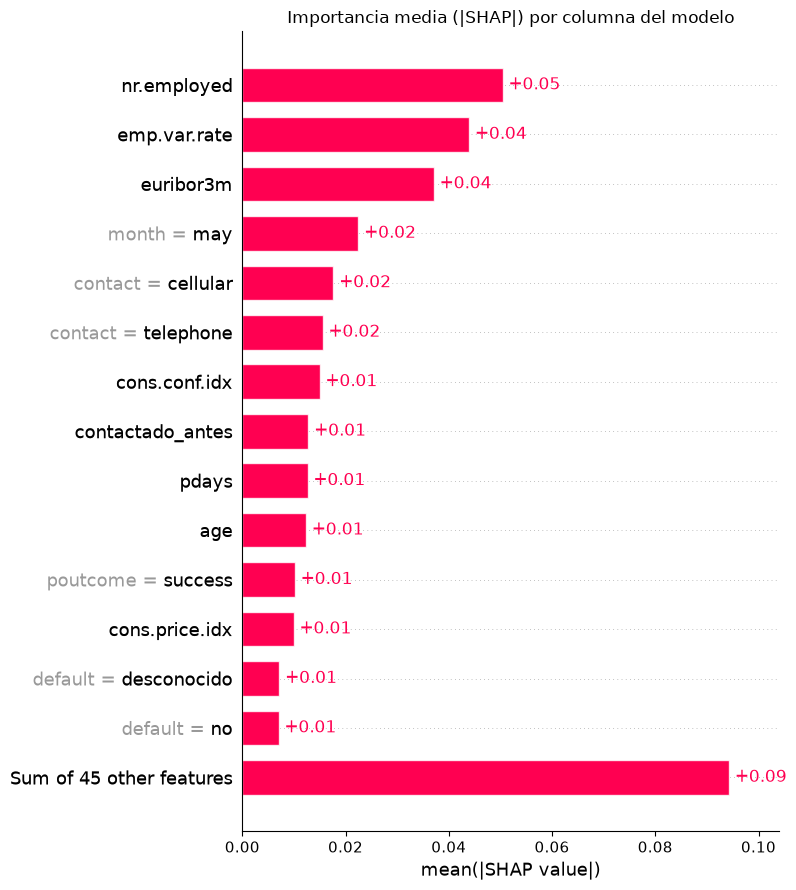

In [4]:
shap.plots.bar(valores, max_display=15, show=False)
plt.title("Importancia media (|SHAP|) por columna del modelo")
plt.tight_layout()
plt.show()

El one-hot reparte cada variable categórica en varias columnas (`contact = cellular` y `contact = telephone`, por ejemplo), así que su importancia aparece dividida. Para comparar **variables completas**, sumamos en cada cliente los valores SHAP de todas las columnas de una misma variable (SHAP es aditivo, así que se puede) y hacemos la media en valor absoluto.

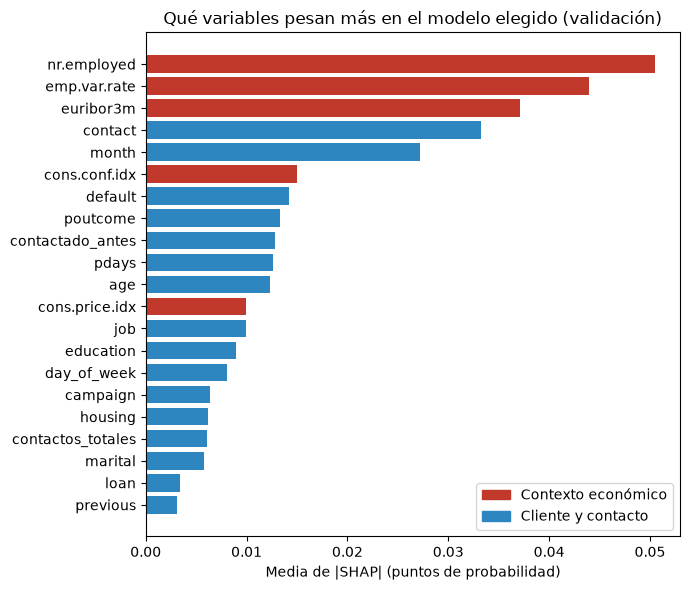

nr.employed          5.05
emp.var.rate         4.40
euribor3m            3.71
contact              3.32
month                2.72
cons.conf.idx        1.50
default              1.42
poutcome             1.33
contactado_antes     1.28
pdays                1.27
age                  1.23
cons.price.idx       1.00
job                  1.00
education            0.89
day_of_week          0.80
campaign             0.63
housing              0.62
contactos_totales    0.61
marital              0.58
loan                 0.34
previous             0.31
Name: media |SHAP| (puntos %), dtype: float64

In [5]:
variable_de_columna = [n.split(" = ")[0] for n in nombres]
shap_por_variable = (
    pd.DataFrame(valores.values, columns=variable_de_columna)
    .T.groupby(level=0).sum().T
)
importancia = shap_por_variable.abs().mean().sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
colores = ["#c0392b" if v in ["euribor3m", "nr.employed", "emp.var.rate", "cons.conf.idx",
                              "cons.price.idx"] else "#2e86c1" for v in importancia.index]
ax.barh(importancia.index, importancia.values, color=colores)
ax.set_xlabel("Media de |SHAP| (puntos de probabilidad)")
ax.set_title("Qué variables pesan más en el modelo elegido (validación)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="#c0392b"),
                   plt.Rectangle((0, 0), 1, 1, color="#2e86c1")],
          labels=["Contexto económico", "Cliente y contacto"], loc="lower right")
fig.tight_layout()
RESULTADOS.mkdir(exist_ok=True)
fig.savefig(RESULTADOS / "shap_importancia.png", dpi=150, bbox_inches="tight")
plt.show()

(importancia.sort_values(ascending=False) * 100).round(2).rename("media |SHAP| (puntos %)")

**Qué vemos:**

- **El contexto económico es lo que más pesa.** Las tres primeras variables son el número de empleados del país (`nr.employed`, 5,1 puntos de media), la variación del empleo (`emp.var.rate`, 4,4) y el euríbor (`euribor3m`, 3,7). Junto con la confianza del consumidor y el IPC, las **cinco variables económicas suman casi la mitad (≈47 %) de toda la importancia**. Están correlacionadas entre sí (0,91-0,97 en el EDA), así que en el fondo dicen lo mismo: en qué momento económico se hizo la llamada.
- **Después, cómo y cuándo se llama:** el tipo de teléfono (`contact`, 3,3) y el mes (`month`, 2,7).
- **El historial con el banco:** `poutcome`, `contactado_antes` y `pdays` pesan ≈1,3 cada una, pero son tres formas de la misma información (si se le contactó en la campaña anterior y cómo fue). Juntas, sumarían ≈3,9 puntos: la primera variable propia del cliente.
- **Los datos personales pesan poco:** edad, trabajo, estudios, estado civil o préstamos mueven la `p` un punto o menos de media. El número de llamadas de esta campaña (`campaign`) tampoco pesa mucho (0,6).

Es coherente con el EDA: con el euríbor por debajo de 1 contrataba ≈45 % de los clientes, y haber sido contactado antes multiplicaba por siete la tasa de contratación.

## 4. ¿En qué dirección empuja cada variable?

El gráfico de barras dice **cuánto** pesa cada variable, pero no **hacia dónde**. El gráfico de enjambre (`beeswarm`) pinta un punto por cliente:

- **Posición horizontal:** su valor SHAP. A la derecha sube la `p`; a la izquierda la baja.
- **Color:** el valor de la variable para ese cliente. Rojo = alto, azul = bajo (en las columnas one-hot, rojo = sí, azul = no).

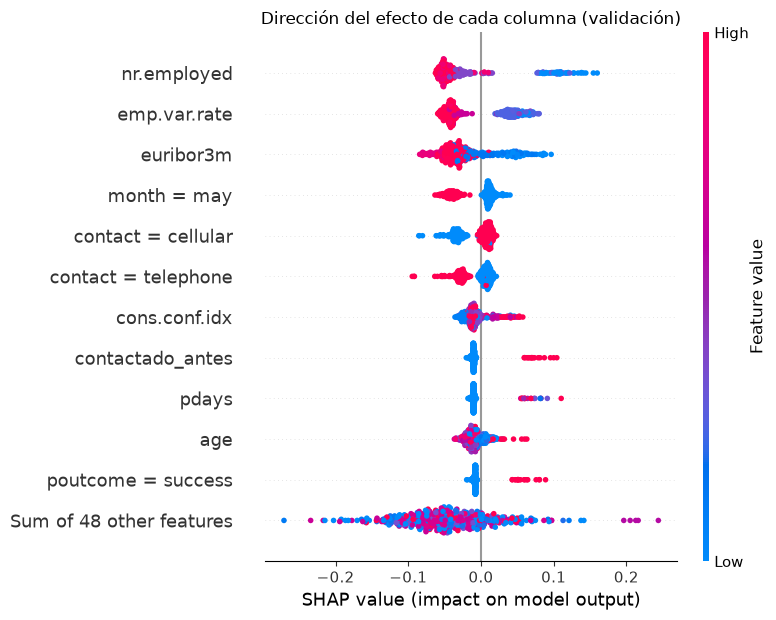

In [6]:
shap.plots.beeswarm(valores, max_display=12, show=False)
plt.title("Dirección del efecto de cada columna (validación)")
plt.tight_layout()
plt.savefig(RESULTADOS / "shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()

**Qué vemos:**

- **Economía débil → `p` más alta.** En `nr.employed`, `emp.var.rate` y `euribor3m` los puntos azules (valores bajos) están a la derecha: con poco empleo y el euríbor bajo, el modelo sube la `p` hasta 0,15 puntos. Con valores altos (rojo), la baja. Son los meses de 2009-2010, en plena crisis, cuando los depósitos eran una opción atractiva y la campaña contrataba mucho más.
- **Llamar en mayo baja la `p`** (≈−0,04): en mayo se hicieron muchísimas llamadas y la tasa de contratación fue de las más bajas del EDA.
- **Móvil sube, teléfono fijo baja.** `contact = cellular` empuja a la derecha y `contact = telephone` a la izquierda.
- **El historial es la señal más fuerte por cliente.** `contactado_antes = 1`, `pdays` alto (es decir, sí hubo contacto anterior, porque 0 = no contactado) y `poutcome = success` suben la `p` entre 0,05 y 0,11 cuando se dan. Afectan a pocos clientes, pero cuando aparecen, mueven mucho.
- **La edad apenas mueve la `p`**, salvo algunos clientes mayores (puntos rojos a la derecha), en línea con la tasa alta de los jubilados en el EDA.

## 5. Explicar un cliente concreto

El gráfico de **cascada** (`waterfall`) es el "ticket" de un cliente. Se lee de abajo arriba: parte del valor de partida (`E[f(X)]` = 0,50), cada barra roja sube la `p` y cada azul la baja, y arriba (`f(x)`) queda la `p` del modelo. A la izquierda de cada barra está el valor que tiene ese cliente.

Vemos dos clientes de validación: el que contrató con la `p` más alta y el que no contrató con la `p` más baja.

Cliente que contrató: p = 0.982


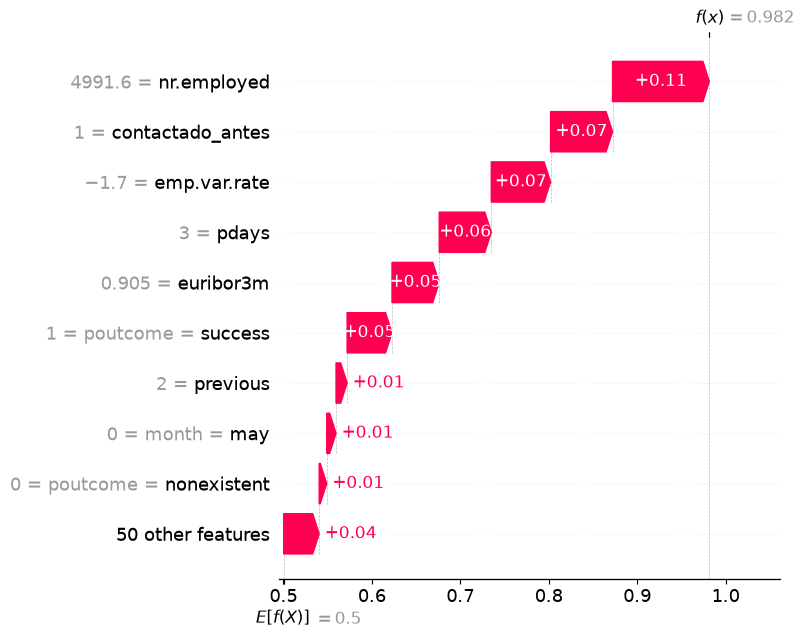

In [7]:
posiciones = np.arange(N_CLIENTES)
contrata = y_muestra.to_numpy() == 1
cliente_si = posiciones[contrata][np.argmax(p[contrata])]
cliente_no = posiciones[~contrata][np.argmin(p[~contrata])]

print(f"Cliente que contrató: p = {p[cliente_si]:.3f}")
shap.plots.waterfall(valores[cliente_si], max_display=10, show=False)
plt.tight_layout()
plt.savefig(RESULTADOS / "shap_cascada.png", dpi=150, bbox_inches="tight")
plt.show()

**Cliente que contrató (p = 0,982).** Parte de 0,50 y todo suma:

- **Contexto económico favorable: +0,23.** Pocos empleados en el país (`nr.employed` = 4.991,6, +0,11), empleo cayendo (`emp.var.rate` = −1,7, +0,07) y euríbor bajo (0,905 %, +0,05).
- **Historial muy bueno: +0,18.** Se le contactó en la campaña anterior (`contactado_antes`, +0,07), hace solo 3 días (`pdays`, +0,06), y **aquella vez contrató** (`poutcome = success`, +0,05).
- No se le llamó en mayo (+0,01).

Es justo el perfil que el EDA señalaba como el más propenso. Con las reglas de negocio actuales, este cliente iría a **R4 · `LLAMAR_AHORA`**.

Cliente que no contrató: p = 0.047


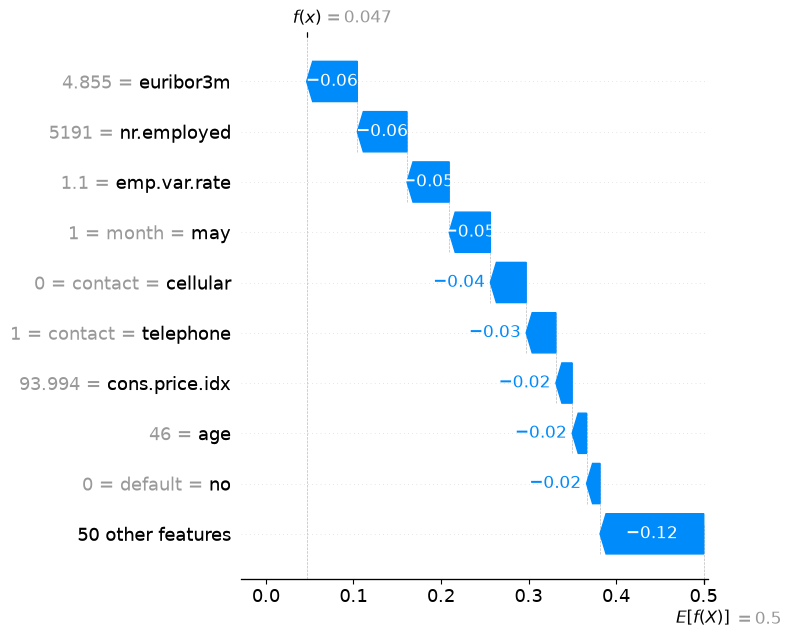

In [8]:
print(f"Cliente que no contrató: p = {p[cliente_no]:.3f}")
shap.plots.waterfall(valores[cliente_no], max_display=10, show=False)
plt.tight_layout()
plt.show()

**Cliente que no contrató (p = 0,047).** Parte de 0,50 y todo resta:

- **Contexto económico desfavorable: −0,17.** Euríbor alto (4,855 %, −0,06), mucho empleo (`nr.employed` = 5.191, −0,06) y empleo creciendo (`emp.var.rate` = 1,1, −0,05). Es el periodo anterior a la crisis, en 2008.
- **Llamada en mayo (−0,05) y a teléfono fijo (−0,07** sumando `contact = cellular` y `contact = telephone`).
- Pequeñas restas de la edad (46 años) y del IPC, y el resto de variables juntas (−0,12).

Nada empuja hacia arriba. Con `p` < 0,113 iría a **R9 · `NO_LLAMAR`**.

## 6. Registro en MLflow

Guardamos los gráficos de SHAP como artefactos de una ejecución del experimento común, junto con la importancia media de cada variable.

In [9]:
mlflow.set_tracking_uri(MLFLOW_URI)
mlflow.set_experiment(EXPERIMENTO)
with mlflow.start_run(run_name="shap_modelo_elegido"):
    mlflow.log_params({"modelo": "RandomForestClassifier", "datos": "validacion (20 % de train)",
                       "n_clientes": N_CLIENTES})
    mlflow.log_metrics({f"shap_{v.replace('.', '_')}": float(i) for v, i in importancia.items()})
    for nombre in ["shap_importancia.png", "shap_beeswarm.png", "shap_cascada.png"]:
        mlflow.log_artifact(str(RESULTADOS / nombre))
print("Registrado en MLflow: shap_modelo_elegido")

Registrado en MLflow: shap_modelo_elegido


## 7. Conclusiones

- **El modelo decide sobre todo por el momento económico** (≈47 % de la importancia): empleo, variación del empleo y euríbor. Después, por **cómo y cuándo se llama** (móvil mejor que fijo, mayo peor) y por el **historial con el banco** (haber contratado en la campaña anterior es la señal individual más fuerte).
- **Los datos personales del cliente pesan poco.** El modelo no distingue tanto *a quién* llamar como *cuándo* y *cómo*.
- **El modelo tiene sentido:** lo que más usa coincide con lo que encontramos en el EDA, y no se apoya en nada absurdo ni en fugas de datos (`duration` está eliminada).

**Cuidado:**

- **SHAP explica el modelo, no la realidad, y no demuestra causas.** Que llamar en mayo reste no significa que llamar en octubre vaya a vender más: en mayo de 2008 se llamó a mucha gente con el euríbor alto.
- **Dependencia del contexto económico.** Las variables económicas describen el momento de la llamada, no al cliente. Si el modelo se usa hoy, su `p` dependerá sobre todo de la situación económica actual, que puede no parecerse a la de 2008-2010. Por eso en las limitaciones del README proponemos probar una separación train/test por fechas.
- **Probabilidades infladas por `class_weight="balanced"`** (valor de partida 0,50 frente a un 11 % real): la `p` sirve para ordenar clientes, pero los umbrales de `src/reglas.py` hay que fijarlos con las probabilidades de este modelo en validación.